In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import sympy as sp
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv("/content/clean_titanic.csv")

In [4]:
df.shape

(889, 20)

In [5]:
X, y = df[['Fare']], df[['Survived']]
lr = LinearRegression().fit(X, y)
lr.predict([[0], [200], [512]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([[0.30227914],
       [0.80185135],
       [1.581184  ]])

In [6]:
def sigmoid(z): return 1 / (1 + np.exp(-z))

print(f"z=-2 => {sigmoid(-2):.3f}")
print(f"z=0 => {sigmoid(0):.3f}")
print(f"z=0.5 => {sigmoid(0.5):.3f}")
print(f"z=2 => {sigmoid(2):.3f}")

z=-2 => 0.119
z=0 => 0.500
z=0.5 => 0.622
z=2 => 0.881


In [7]:
x = sp.symbols('x')

def z(w, b, x): return w * x + b
print(f"w = 2.5, b=-1.4, x=0 -> {z(2.5, -1.4, 0)}")
print(f"w = 2.5, b=-1.4, x=1 -> {z(2.5, -1.4, 1)}")

w = 2.5, b=-1.4, x=0 -> -1.4
w = 2.5, b=-1.4, x=1 -> 1.1


[np.float64(-6.0), np.float64(-5.0), np.float64(-4.0), np.float64(-3.0), np.float64(-2.0), np.float64(-1.0), np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0), np.float64(6.0)]


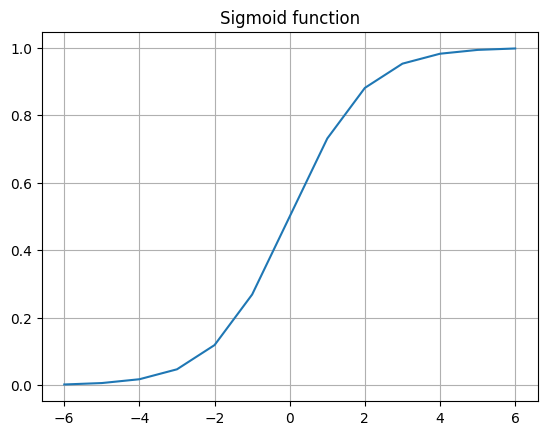

In [8]:
nums = []
for step in np.linspace(-6, 6, 13):
  nums.append(step)

print(nums)
plt.plot(nums, [sigmoid(x) for x in nums])
plt.grid(True)
plt.title("Sigmoid function")
plt.show()

In [9]:
df['Age'] = df.Age.fillna(df.Age.median())
df['Embarked'] = df.Embarked.fillna('S')

df['Sex'] = df.Sex.map({"male": 0, "female": 1})

# Embarked - 3 qiymat, one-hot
df = pd.get_dummies(df, columns=['Embarked'], drop_first=True)

In [10]:
df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,family_size,...,Title,fare_per_person,Sex_encoded,Embarked_C,Embarked_Q,Embarked_S,Age_scaled,Fare_std,Embarked_Q,Embarked_S
0,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,2,...,Mr,3.62500,1,False,False,True,0.271174,-0.500240,False,True
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,2,...,Mrs,35.64165,0,True,False,False,0.472229,0.788947,False,False
2,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,1,...,Miss,7.92500,0,False,False,True,0.321438,-0.486650,False,True
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,2,...,Mrs,26.55000,0,False,False,True,0.434531,0.422861,False,True
4,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,1,...,Mr,8.05000,1,False,False,True,0.434531,-0.484133,False,True


In [11]:
df['FamilySize'] = df.SibSp + df.Parch + 1
df['IsAlone'] = (df.FamilySize == 1).astype(int)

In [12]:
X, y = df[['Fare']], df['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler().fit(X_train)
X_train_s = sc.transform(X_train)
X_test_s = sc.transform(X_test)

In [14]:
print(f"0 < age <= 15 -> {len(df[(df.Age > 0) & (df.Age <= 15)])}")
print(f"15 < age <= 30 -> {len(df[(df.Age > 15) & (df.Age <= 30)])}")
print(f"30 < age <= 45 -> {len(df[(df.Age > 30) & (df.Age <= 45)])}")
print(f"45 < age -> {len(df[df.Age > 45])}")

0 < age <= 15 -> 83
15 < age <= 30 -> 503
30 < age <= 45 -> 201
45 < age -> 102


In [15]:
from sklearn.linear_model import LogisticRegression

feats = ["Pclass", "Sex", "Age", "Fare", "FamilySize", "IsAlone", "Embarked_Q", "Embarked_S"]

Xtr, Xte, ytr, yte = train_test_split(df[feats], y, test_size=0.2, random_state=42, stratify=y)

sc = StandardScaler().fit(Xtr)
m = LogisticRegression(max_iter=1000)
m.fit(sc.transform(Xtr), ytr)
print(f"Accuracy: {m.score(sc.transform(Xte), yte)}")

Accuracy: 0.8202247191011236


In [16]:
Xte_s = sc.transform(Xte)

print("Predictions:")
display(m.predict(Xte_s)[:5])

print("Probabilities:")
display(m.predict_proba(Xte_s)[:2])

Predictions:


array([0, 0, 0, 0, 0])

Probabilities:


array([[0.92574807, 0.07425193],
       [0.83917771, 0.16082229]])

In [17]:
feats = ["Pclass", "Sex", "Age"]

y = df["Survived"]
Xtr, Xte, ytr, yte = train_test_split(df[feats], y, test_size=0.2, random_state=42, stratify=y)

sc = StandardScaler().fit(Xtr)
m = LogisticRegression(max_iter=1000)
m.fit(sc.transform(Xtr), ytr)
print(f"Accuracy: {m.score(sc.transform(Xte), yte)}")

Accuracy: 0.7921348314606742


In [18]:
feats = ['Pclass', 'Sex', 'Age']

person = {
 "Pclass": 3,
 'Sex': 0,
 "Age": 20
}

person_df = pd.DataFrame([person])[feats]

person_scaled = sc.transform(person_df)

prediction = m.predict(person_scaled)[0]

probabilities = m.predict_proba(person_scaled)[0]

status = "Tirik qolgan (Survived)" if prediction == 1 else "Vafot etgan (Not Survived)"
print(f"Bashorat: {status}")
print(f"Tirik qolish ehtimoli: {probabilities[1] * 100:.2f}%")

Bashorat: Vafot etgan (Not Survived)
Tirik qolish ehtimoli: 11.66%


In [19]:
from sklearn.metrics import confusion_matrix, classification_report

# Model 3 ta ustunga moslangan, shuning uchun test ma'lumotlarini qayta masshtablaymiz
Xte_scaled = sc.transform(Xte)
pred = m.predict(Xte_scaled)

print(confusion_matrix(yte, pred))
print(classification_report(yte, pred))
# FP qimmat --> Precision'ga e'tibor bering.
# FN qimmat --> Recall'ga e'tibor bering.
# Precision = TP / (TP + FP)
# Recall = TP / (TP + FN)

[[94 16]
 [21 47]]
              precision    recall  f1-score   support

           0       0.82      0.85      0.84       110
           1       0.75      0.69      0.72        68

    accuracy                           0.79       178
   macro avg       0.78      0.77      0.78       178
weighted avg       0.79      0.79      0.79       178



In [20]:
# "Hamma o'ladi" baseline (barcha bashoratlar 0)
baseline_pred = np.zeros_like(yte)

print("Baseline Confusion Matrix:")
print(confusion_matrix(yte, baseline_pred))
print("\nBaseline Classification Report:")
print(classification_report(yte, baseline_pred, zero_division=0))

# Logistic Regression modeli: Tirik qolganlar (1 class) uchun Recall 0.69 (yoki ~69%).
# Ya'ni haqiqatda tirik qolganlarning 69% ini modelimiz to'g'ri topa olgan.
# "Hamma o'ladi" baseline modeli: Tirik qolganlar (1 class) uchun Recall 0.00 (0%).
# Chunki bu model hech kimni tirik qoldi deb topa olmaydi (barcha True Positive-lar 0 ga teng).

Baseline Confusion Matrix:
[[110   0]
 [ 68   0]]

Baseline Classification Report:
              precision    recall  f1-score   support

           0       0.62      1.00      0.76       110
           1       0.00      0.00      0.00        68

    accuracy                           0.62       178
   macro avg       0.31      0.50      0.38       178
weighted avg       0.38      0.62      0.47       178



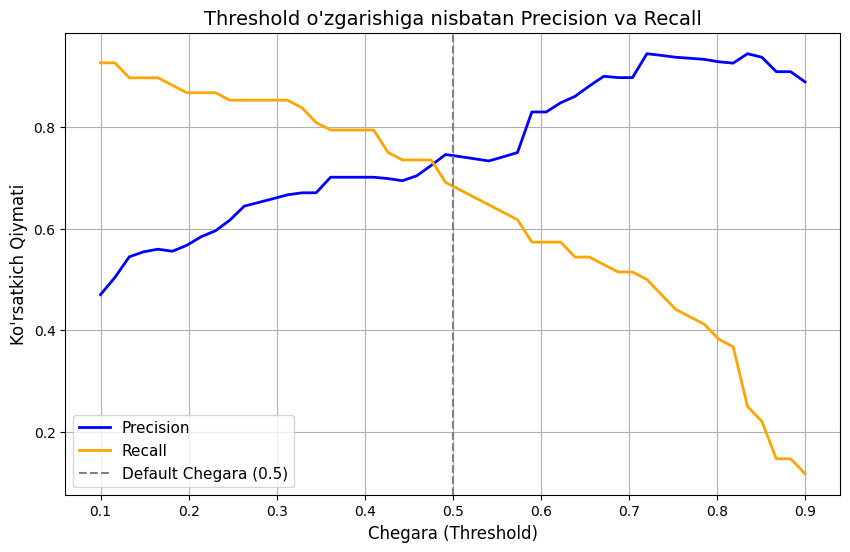

In [21]:
from sklearn.metrics import precision_score, recall_score

# Ehtimolliklarni olish (tirik qolish sinfi uchun: index 1)
probs = m.predict_proba(Xte_scaled)[:, 1]

thresholds = np.linspace(0.1, 0.9, 50)
precisions = []
recalls = []

for t in thresholds:
    preds_t = (probs >= t).astype(int)
    precisions.append(precision_score(yte, preds_t, zero_division=0))
    recalls.append(recall_score(yte, preds_t, zero_division=0))

plt.figure(figsize=(10, 6))
plt.plot(thresholds, precisions, label='Precision', color='blue', linewidth=2)
plt.plot(thresholds, recalls, label='Recall', color='orange', linewidth=2)
plt.title('Threshold o\'zgarishiga nisbatan Precision va Recall', fontsize=14)
plt.xlabel('Chegara (Threshold)', fontsize=12)
plt.ylabel('Ko\'rsatkich Qiymati', fontsize=12)
plt.axvline(x=0.5, color='gray', linestyle='--', label='Default Chegara (0.5)')
plt.grid(True)
plt.legend(fontsize=11)
plt.show()

In [22]:
## =============== homework session ================= ##

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86       110
           1       0.80      0.71      0.75        68

    accuracy                           0.82       178
   macro avg       0.82      0.80      0.80       178
weighted avg       0.82      0.82      0.82       178



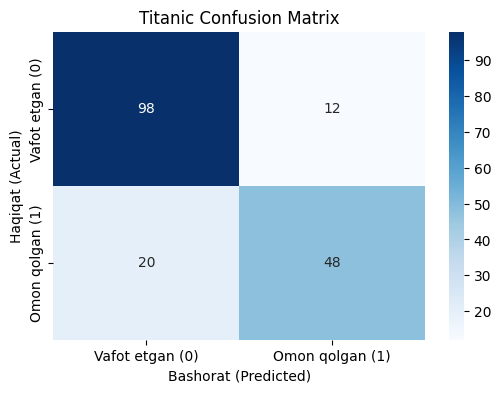

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Asosiy xususiyatlar ro'yxati
features = [
    "Pclass",
    "Sex",
    "Age",
    "Fare",
    "FamilySize",
    "IsAlone",
    "Embarked_Q",
    "Embarked_S",
]
X = df[features]
y = df["Survived"]

# 2. Train va Test ga ajratish
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Masshtablash (Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Modelni o'qitish
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# 5. Bashorat va Confusion Matrix
y_pred = model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred)

print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix vizualizatsiyasi
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Vafot etgan (0)", "Omon qolgan (1)"],
    yticklabels=["Vafot etgan (0)", "Omon qolgan (1)"],
)
plt.xlabel("Bashorat (Predicted)")
plt.ylabel("Haqiqat (Actual)")
plt.title("Titanic Confusion Matrix")
plt.show()

In [24]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

# 1-sinf (omon qolganlar) uchun ehtimolliklar
y_probs = model.predict_proba(X_test_scaled)[:, 1]

thresholds = np.arange(0.1, 1.0, 0.1)
table_data = []

for t in thresholds:
  t = round(t, 2)
  preds = (y_probs >= t).astype(int)
  acc = accuracy_score(y_test, preds)
  prec = precision_score(y_test, preds, zero_division=0)
  rec = recall_score(y_test, preds, zero_division=0)
  f1 = f1_score(y_test, preds, zero_division=0)

  table_data.append({
      "Chegara (Threshold)": t,
      "Accuracy": round(acc, 4),
      "Precision": round(prec, 4),
      "Recall": round(rec, 4),
      "F1-Score": round(f1, 4),
  })

threshold_df = pd.DataFrame(table_data)
display(threshold_df)

,Chegara (Threshold),Accuracy,Precision,Recall,F1-Score
0,0.1,0.5225,0.4414,0.9412,0.6009
1,0.2,0.7247,0.5941,0.8824,0.7101
2,0.3,0.7921,0.6867,0.8382,0.7550
3,0.4,0.8034,0.7200,0.7941,0.7552
4,0.5,0.8202,0.8000,0.7059,0.7500
5,0.6,0.8371,0.8679,0.6765,0.7603
6,0.7,0.7809,0.8537,0.5147,0.6422
7,0.8,0.7528,0.9286,0.3824,0.5417
8,0.9,0.6742,0.9167,0.1618,0.2750


In [25]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Baseline uchun asosiy ustunlar
base_features = [
    "Pclass",
    "Sex",
    "Age",
    "Fare",
    "FamilySize",
    "IsAlone",
    "Embarked_Q",
    "Embarked_S",
]
pipeline = make_pipeline(
    StandardScaler(), LogisticRegression(max_iter=1000, random_state=42)
)

# 0. Baseline CV natijasi
cv_base = cross_val_score(
    pipeline, df[base_features], df["Survived"], cv=5, scoring="accuracy"
)
print(f"Baseline 5-Fold CV Accuracy: {cv_base.mean():.4f} (±{cv_base.std():.4f})")

# -------------------------------------------------------------
# 1-Yangi Feature: Title (Ismlardan unvon ajratish)
# Agar darsda df['Title'] allaqachon yaratilgan bo'lsa, o'shandan foydalanamiz
if "Title" not in df.columns:
  df["Title"] = df["Name"].str.extract(" ([A-Za-z]+)\.", expand=False)
  df["Title"] = df["Title"].replace(
      [
          "Lady",
          "Countess",
          "Capt",
          "Col",
          "Don",
          "Dr",
          "Major",
          "Rev",
          "Sir",
          "Jonkheer",
          "Dona",
      ],
      "Rare",
  )
  df["Title"] = df["Title"].replace("Mlle", "Miss")
  df["Title"] = df["Title"].replace("Ms", "Miss")
  df["Title"] = df["Title"].replace("Mme", "Mrs")

# Title ustunini One-Hot Encoding qilamiz
df_title = pd.get_dummies(df["Title"], prefix="Title", drop_first=True)
title_features = list(df_title.columns)

df_with_title = pd.concat([df, df_title], axis=1)

features_f1 = base_features + title_features
cv_f1 = cross_val_score(
    pipeline,
    df_with_title[features_f1],
    df_with_title["Survived"],
    cv=5,
    scoring="accuracy",
)
print(
    f"+ Feature 1 (Title) CV Accuracy: {cv_f1.mean():.4f} (Farq: {cv_f1.mean() - cv_base.mean():+.4f})"
)

# 2-Yangi Feature: Age_Class (Yosh va Chipta klassi ko'paytmasi)
df_with_title["Age_Class"] = df_with_title["Age"] * df_with_title["Pclass"]

features_f2 = features_f1 + ["Age_Class"]
cv_f2 = cross_val_score(
    pipeline,
    df_with_title[features_f2],
    df_with_title["Survived"],
    cv=5,
    scoring="accuracy",
)
print(
    f"+ Feature 2 (Age_Class) CV Accuracy: {cv_f2.mean():.4f} (Farq: {cv_f2.mean() - cv_f1.mean():+.4f})"
)

<>:33: SyntaxWarning: invalid escape sequence '\.'
<>:33: SyntaxWarning: invalid escape sequence '\.'
/tmp/ipykernel_906/3395840736.py:33: SyntaxWarning: invalid escape sequence '\.'
  df["Title"] = df["Name"].str.extract(" ([A-Za-z]+)\.", expand=False)


Baseline 5-Fold CV Accuracy: 0.7953 (±0.0158)
+ Feature 1 (Title) CV Accuracy: 0.8212 (Farq: +0.0259)
+ Feature 2 (Age_Class) CV Accuracy: 0.8223 (Farq: +0.0011)
